# PoseFlow V5 versus V9 joint-query attention

**Question.** How large are the joint self-attention QK logits, where does V5 attend, and how does V9's learned nonneighbor logit bias change the actual attention probabilities?

This notebook measures the **clean expanded joint-query self-attention** of the refiner. Both models use the same grouped `nn.MultiheadAttention` implementation. V5 has a hard mask between person groups. V9 keeps that hard mask and adds one learned scalar to each within-person, nonneighbor joint-to-joint logit. The person box token, self links, and skeleton edges do not receive that scalar.

We compare matched final epoch-79 checkpoints on the same eight CrowdPose validation images, resize, three-step sampler, and per-image source seed. We also rerun V9 with its three bias parameters temporarily set to zero and calculate a **same-QK zero-bias softmax** inside each captured forward. The replay changes later activations; the same-QK calculation isolates the immediate softmax effect at each layer.

The attention trace uses eight images. A separate 20-image fixed subset below reports diagnostic bbox and keypoint AP; it is too small to estimate full-validation AP reliably. Cross-checkpoint differences include all weights learned during separate training runs.

In [1]:
from pathlib import Path
from contextlib import contextmanager
import math
import os
import sys
import io
import json
import contextlib

ROOT = Path.cwd()
if not (ROOT / 'AGENTS.md').is_file():
    ROOT = ROOT.parents[1]
assert (ROOT / 'AGENTS.md').is_file(), 'Run from the repository root or the notebook directory.'
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.nn import functional as F
from IPython import get_ipython
from IPython.display import Image, display

get_ipython().run_line_magic('matplotlib', 'inline')

FIGURE_DIR = ROOT / 'tmp/poseflow_v5_v9_joint_attention/figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def show_figure(fig, filename=None):
    if filename is not None:
        fig.savefig(FIGURE_DIR / filename, dpi=160, bbox_inches='tight')
    image = io.BytesIO()
    fig.savefig(image, format='png', dpi=140, bbox_inches='tight')
    display(Image(data=image.getvalue()))
    plt.close(fig)

from scripts.evaluation.evaluate_poseflow import load_poseflow_model, seed_flow_sampling
from src.data.datasets import PoseDataset
from src.data.io import read_image
from src.data.skeleton import CROWDPOSE_EDGE_LIST
from src.models.pipelines.pose_estimators.diffusionregpose.evaluation import (
    resize_crowdpose_eval_image, postprocess_crowdpose, crowdpose_result_records,
    write_crowdpose_results, evaluate_crowdpose_results,
)

RUNS = {
    'V5': ROOT / 'results/poseflow_v5_training/poseflow_v5_training/20260917_121833',
    'V9': ROOT / 'results/poseflow_v9_training/poseflow_v9_training/20261001_191119',
}
ANNOTATIONS = ROOT / 'data/crowdpose/annotations/crowdpose_val.json'
IMAGE_ROOT = ROOT / 'data/crowdpose/images'
FLOW_SEED = 1729
SAMPLING_STEPS = 3
IMAGE_COUNT = 8
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dataset = PoseDataset.from_path(ANNOTATIONS, img_root=IMAGE_ROOT, num_keypoints=14)
samples = sorted(dataset.samples, key=lambda item: item['image_id'])[:IMAGE_COUNT]
IMAGE_IDS = [sample['image_id'] for sample in samples]
for family, run in RUNS.items():
    assert (run / 'checkpoints/epoch079.ckpt').is_file()
    assert (run / '.hydra/config.yaml').is_file()
print({'device': str(DEVICE), 'checkpoint_epoch': 79, 'sampling_steps': SAMPLING_STEPS,
       'flow_seed_rule': '1729 + image_id', 'image_ids': IMAGE_IDS,
       'preprocessing': 'aspect-preserving 256/427; ImageNet normalization',
       'checkpoints': {family: str(run / 'checkpoints/epoch079.ckpt') for family, run in RUNS.items()},
       'configs': {family: str(run / '.hydra/config.yaml') for family, run in RUNS.items()}})

{'device': 'cuda', 'checkpoint_epoch': 79, 'sampling_steps': 3, 'flow_seed_rule': '1729 + image_id', 'image_ids': [100018, 100038, 100039, 100040, 100065, 100069, 100108, 100114], 'preprocessing': 'aspect-preserving 256/427; ImageNet normalization', 'checkpoints': {'V5': '/home/gasparyanartur/dev/pose-graph-diff/results/poseflow_v5_training/poseflow_v5_training/20260917_121833/checkpoints/epoch079.ckpt', 'V9': '/home/gasparyanartur/dev/pose-graph-diff/results/poseflow_v9_training/poseflow_v9_training/20261001_191119/checkpoints/epoch079.ckpt'}, 'configs': {'V5': '/home/gasparyanartur/dev/pose-graph-diff/results/poseflow_v5_training/poseflow_v5_training/20260917_121833/.hydra/config.yaml', 'V9': '/home/gasparyanartur/dev/pose-graph-diff/results/poseflow_v9_training/poseflow_v9_training/20261001_191119/.hydra/config.yaml'}}


## What is being measured

The attention module receives `query = key = target + query_position`. We apply its learned query/key projections, split the eight heads, and form `QKᵀ / √32`. Only the 14 joint-query rows and 15 keys in the same person group (box plus 14 joints) are included. We classify each key as **box**, **self**, **skeleton neighbor**, or **nonneighbor**. Raw-logit quantiles below exclude cross-person `−∞` mask values. A rowwise constant offset is invisible to softmax, so row-centered QK spread is reported as well as raw quantiles. The returned PyTorch attention weights provide an independent reconstruction check.

In [2]:
def relation_masks(device):
    adjacency = torch.eye(14, dtype=torch.bool, device=device)
    for source, destination in CROWDPOSE_EDGE_LIST:
        adjacency[source, destination] = True
        adjacency[destination, source] = True
    query = torch.arange(14, device=device)
    key = torch.arange(14, device=device)
    relations = {
        'box': torch.zeros(14, 15, dtype=torch.bool, device=device),
        'self': torch.zeros(14, 15, dtype=torch.bool, device=device),
        'neighbor': torch.zeros(14, 15, dtype=torch.bool, device=device),
        'nonneighbor': torch.zeros(14, 15, dtype=torch.bool, device=device),
    }
    relations['box'][:, 0] = True
    relations['self'][:, 1:] = query[:, None] == key[None, :]
    relations['neighbor'][:, 1:] = adjacency & ~torch.eye(14, dtype=torch.bool, device=device)
    relations['nonneighbor'][:, 1:] = ~adjacency
    assert sum(mask.int() for mask in relations.values()).eq(1).all()
    return relations


@contextmanager
def capture_joint_attention(model, variant, image_id):
    decoder = model.transformer.decoder
    group_count, group_size = decoder.num_group, decoder.num_body_points + 1
    assert group_size == 15
    records, pending, handles = [], {}, []
    calls = [0] * len(decoder.layers)

    def make_pre_hook(layer_index):
        def pre_hook(module, inputs, kwargs):
            query = inputs[0].detach().transpose(0, 1)
            batch_size, token_count, width = query.shape
            head_count = module.num_heads
            assert token_count == group_count * group_size
            head_width = width // head_count
            projection_bias = module.in_proj_bias
            q_bias = None if projection_bias is None else projection_bias[:width]
            k_bias = None if projection_bias is None else projection_bias[width:2 * width]
            q = F.linear(query, module.in_proj_weight[:width], q_bias)
            k = F.linear(query, module.in_proj_weight[width:2 * width], k_bias)
            q = q.reshape(batch_size, group_count, group_size, head_count, head_width).permute(0, 1, 3, 2, 4)
            k = k.reshape(batch_size, group_count, group_size, head_count, head_width).permute(0, 1, 3, 2, 4)
            value_input = inputs[2].detach().transpose(0, 1)
            v_bias = None if projection_bias is None else projection_bias[2 * width:3 * width]
            v = F.linear(value_input, module.in_proj_weight[2 * width:3 * width], v_bias)
            v = v.reshape(batch_size, group_count, group_size, head_count, head_width).permute(0, 1, 3, 2, 4)
            raw = (q[..., 1:, :] @ k.transpose(-2, -1)).float() / math.sqrt(head_width)

            mask = kwargs['attn_mask']
            if mask.ndim == 2:
                mask = mask[None, None].expand(batch_size, head_count, -1, -1)
            else:
                assert mask.shape == (batch_size * head_count, token_count, token_count)
                mask = mask.reshape(batch_size, head_count, token_count, token_count)
            if mask.dtype == torch.bool:
                mask = torch.zeros_like(mask, dtype=torch.float32).masked_fill(mask, -torch.inf)
            else:
                mask = mask.float()
            blocks = torch.stack([
                mask[:, :, group * group_size + 1:(group + 1) * group_size,
                     group * group_size:(group + 1) * group_size]
                for group in range(group_count)
            ], dim=1)
            assert torch.isfinite(raw).all()
            assert torch.isfinite(blocks).all(), 'All keys inside a clean person group should be allowed.'
            probability = (raw + blocks).softmax(-1)
            hard_only = torch.where(torch.isfinite(blocks), 0.0, -torch.inf)
            same_qk_zero_bias = (raw + hard_only).softmax(-1)
            weighted_value = probability.to(v.dtype) @ v
            clean_value = weighted_value.permute(0, 1, 3, 2, 4).reshape(batch_size, group_count, 14, width)
            reconstructed = module.out_proj(clean_value).float()
            clean_target = value_input.reshape(batch_size, group_count, group_size, width)[:, :, 1:].float()
            value_rms = v.float().square().mean().sqrt()
            weighted_value_rms = weighted_value.float().square().mean().sqrt()
            attention_output_rms = reconstructed.square().mean().sqrt()
            target_rms = clean_target.square().mean().sqrt()
            zero_weighted = same_qk_zero_bias.to(v.dtype) @ v
            zero_concat = zero_weighted.permute(0, 1, 3, 2, 4).reshape(batch_size, group_count, 14, width)
            same_input_difference = module.out_proj(zero_concat).float() - reconstructed
            bias_change_rms = same_input_difference.square().mean().sqrt()
            token_ratios = reconstructed.norm(dim=-1) / clean_target.norm(dim=-1).clamp_min(1e-8)
            ratio_quantiles = torch.quantile(token_ratios.flatten(), token_ratios.new_tensor([.1, .5, .9]))
            assert torch.allclose(probability.sum(-1), torch.ones_like(probability[..., 0]), atol=1e-5)
            relation = relation_masks(raw.device)
            centered = raw - raw.mean(-1, keepdim=True)
            quantiles = torch.quantile(raw.flatten(), torch.tensor([.01, .1, .5, .9, .99], device=raw.device))
            centered_quantiles = torch.quantile(centered.flatten(), torch.tensor([.05, .5, .95], device=raw.device))
            row = {
                'variant': variant, 'image_id': image_id, 'step': calls[layer_index], 'layer': layer_index,
                'bias': float(model.off_edge_attention_bias[layer_index]) if hasattr(model, 'off_edge_attention_bias') else 0.0,
                'raw_q01': float(quantiles[0]), 'raw_q10': float(quantiles[1]),
                'raw_median': float(quantiles[2]), 'raw_q90': float(quantiles[3]), 'raw_q99': float(quantiles[4]),
                'centered_q05': float(centered_quantiles[0]), 'centered_median': float(centered_quantiles[1]),
                'centered_q95': float(centered_quantiles[2]),
                'row_logit_std': float(raw.std(-1, unbiased=False).mean()),
                'row_logit_range': float((raw.amax(-1) - raw.amin(-1)).mean()),
                'value_rms': float(value_rms),
                'weighted_value_rms': float(weighted_value_rms),
                'attention_output_rms': float(attention_output_rms),
                'target_rms': float(target_rms),
                'bias_change_rms': float(bias_change_rms),
                'bias_change_to_input_rms': float(bias_change_rms / target_rms.clamp_min(1e-8)),
                'bias_change_to_update_rms': float(bias_change_rms / attention_output_rms.clamp_min(1e-8)),
                'token_ratio_q10': float(ratio_quantiles[0]),
                'token_ratio_median': float(ratio_quantiles[1]),
                'token_ratio_q90': float(ratio_quantiles[2]),
                'output_to_target_rms': float(attention_output_rms / target_rms),
                'output_target_cosine': float(F.cosine_similarity(reconstructed.flatten(-1), clean_target.flatten(-1)).mean()),
                'matrix': probability.mean((0, 1, 2)).detach().cpu().numpy(),
                'same_qk_zero_matrix': same_qk_zero_bias.mean((0, 1, 2)).detach().cpu().numpy(),
            }
            for label, relation_mask in relation.items():
                selected = relation_mask[None, None, None]
                row[f'{label}_mass'] = float((probability * selected).sum(-1).mean())
                row[f'{label}_mass_same_qk_zero_bias'] = float((same_qk_zero_bias * selected).sum(-1).mean())
                row[f'{label}_raw_median'] = float(raw[..., relation_mask].median())
            pending[layer_index] = (row, probability.mean(2), reconstructed)
            calls[layer_index] += 1
        return pre_hook

    def make_post_hook(layer_index):
        def post_hook(module, inputs, kwargs, output):
            row, expected, reconstructed = pending.pop(layer_index)
            returned = output[1]
            assert returned is not None and returned.ndim == 3
            blocks = torch.stack([
                returned[:, group * group_size + 1:(group + 1) * group_size,
                         group * group_size:(group + 1) * group_size]
                for group in range(group_count)
            ], dim=1)
            difference = (expected - blocks.float()).abs()
            row['weight_reconstruction_max_abs'] = float(difference.max())
            actual_clean = output[0].detach().transpose(0, 1).reshape(
                reconstructed.shape[0], group_count, group_size, reconstructed.shape[-1],
            )[:, :, 1:].float()
            row['output_reconstruction_max_abs'] = float((reconstructed - actual_clean).abs().max())
            assert row['output_reconstruction_max_abs'] < 5e-5
            assert row['weight_reconstruction_max_abs'] < 5e-5
            assert abs(sum(row[f'{name}_mass'] for name in ('box', 'self', 'neighbor', 'nonneighbor')) - 1) < 1e-5
            records.append(row)
        return post_hook

    for layer_index, layer in enumerate(decoder.layers):
        handles.append(layer.self_attn.register_forward_pre_hook(make_pre_hook(layer_index), with_kwargs=True))
        handles.append(layer.self_attn.register_forward_hook(make_post_hook(layer_index), with_kwargs=True))
    try:
        yield records
        assert not pending
    finally:
        for handle in handles:
            handle.remove()


def run_variant(model, variant, sample_rows):
    rows = []
    for sample in sample_rows:
        image_id = sample['image_id']
        image = resize_crowdpose_eval_image(
            read_image(sample['img_path']).float().div(255), shortest_side=256, max_size=427,
        ).to(DEVICE)
        seed_flow_sampling(flow_seed=FLOW_SEED, image_id=image_id)
        hook_counts = [(len(layer.self_attn._forward_pre_hooks), len(layer.self_attn._forward_hooks))
                       for layer in model.transformer.decoder.layers]
        with torch.no_grad(), capture_joint_attention(model, variant, image_id) as captured:
            output = model.sample_keypoints(image[None])
        assert hook_counts == [
            (len(layer.self_attn._forward_pre_hooks), len(layer.self_attn._forward_hooks))
            for layer in model.transformer.decoder.layers
        ]
        assert len(captured) == SAMPLING_STEPS * len(model.transformer.decoder.layers)
        rows.extend(captured)
        if image_id == IMAGE_IDS[0]:
            first_output = {name: output[name].detach().cpu().clone()
                            for name in ('pred_logits', 'pred_boxes', 'pred_keypoints')}
        del image, output
    return rows, first_output


relation = relation_masks(DEVICE)
print('Mean keys per joint query:',
      {name: float(mask.sum(-1).float().mean()) for name, mask in relation.items()})


Mean keys per joint query: {'box': 1.0, 'self': 1.0, 'neighbor': 2.0, 'nonneighbor': 11.000000953674316}


## Capture matched final checkpoints

Models run sequentially on the selected device. The hook performs detached measurement and is removed after each image. The bias-zero run restores the learned V9 parameter even if sampling fails. The first image is sampled again after restoration to verify prediction parity.

In [3]:
all_rows = []
first_outputs = {}
for family in ('V5', 'V9'):
    model, config = load_poseflow_model(
        RUNS[family] / 'checkpoints/epoch079.ckpt', RUNS[family] / '.hydra/config.yaml',
    )
    assert config.num_body_points == 14
    assert config.flow_sampling_steps == SAMPLING_STEPS
    assert int(config.num_decoder_layers) == len(model.transformer.decoder.layers)
    assert int(config.num_feature_levels) == 4
    model.to(DEVICE).eval()
    measured, first = run_variant(model, family, samples)
    all_rows.extend(measured)
    first_outputs[family] = first
    print(family, 'rows:', len(measured), 'max weight error:',
          max(row['weight_reconstruction_max_abs'] for row in measured))
    if family == 'V9':
        learned_bias = model.off_edge_attention_bias.detach().cpu().clone()
        try:
            with torch.no_grad():
                model.off_edge_attention_bias.zero_()
            zero_rows, zero_first = run_variant(model, 'V9 bias=0 replay', samples)
            all_rows.extend(zero_rows)
            first_outputs['V9 bias=0 replay'] = zero_first
        finally:
            with torch.no_grad():
                model.off_edge_attention_bias.copy_(learned_bias.to(model.off_edge_attention_bias))
        torch.testing.assert_close(model.off_edge_attention_bias.cpu(), learned_bias)
        restored_rows, restored_first = run_variant(model, 'V9 restored check', samples[:1])
        for name, value in first.items():
            torch.testing.assert_close(value, restored_first[name], rtol=1e-5, atol=1e-6)
        print('V9 learned bias:', learned_bias.tolist(), 'restored prediction: exact within 1e-6')
    del model
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()

attention = pd.DataFrame([{key: value for key, value in row.items()
                           if key not in ('matrix', 'same_qk_zero_matrix')}
                          for row in all_rows])
assert attention.groupby('variant').size().to_dict() == {
    'V5': 8 * 3 * 3, 'V9': 8 * 3 * 3, 'V9 bias=0 replay': 8 * 3 * 3,
}
print('weight-reconstruction max absolute error:', attention.weight_reconstruction_max_abs.max())
print('output-reconstruction max absolute error:', attention.output_reconstruction_max_abs.max())
display(attention.groupby(['variant', 'layer'])[[
    'bias', 'row_logit_std', 'centered_q05', 'centered_q95',
    'box_mass', 'self_mass', 'neighbor_mass', 'nonneighbor_mass',
]].mean().round(4))

/home/gasparyanartur/dev/pose-graph-diff/venv/lib/python3.10/site-packages/torch/utils/cpp_extension.py:1965: UserWarning: TORCH_CUDA_ARCH_LIST is not set, all archs for visible cards are included for compilation. 
If this is not desired, please set os.environ['TORCH_CUDA_ARCH_LIST'].
  warnings.warn(


V5 rows: 72 max weight error: 5.960464477539062e-07


V9 rows: 72 max weight error: 9.834766387939453e-07


V9 learned bias: [-5.2970805168151855, -5.107131481170654, -4.824189186096191] restored prediction: exact within 1e-6
weight-reconstruction max absolute error: 9.834766387939453e-07
output-reconstruction max absolute error: 7.62939453125e-06


bias  row_logit_std  centered_q05  centered_q95  \
variant          layer                                                      
V5               0      0.0000         1.4184       -2.3940        2.5433   
                 1      0.0000         1.2998       -2.3769        2.2719   
                 2      0.0000         1.9377       -3.4721        3.5272   
V9               0     -5.2971         2.0332       -3.7310        3.5738   
                 1     -5.1071         1.9128       -3.5943        3.4802   
                 2     -4.8242         2.3926       -4.2231        4.4994   
V9 bias=0 replay 0      0.0000         2.0338       -3.7314        3.5745   
                 1      0.0000         1.4680       -2.8063        2.6893   
                 2      0.0000         1.6346       -3.0333        3.1002   

                        box_mass  self_mass  neighbor_mass  nonneighbor_mass  
variant          layer                                                        
V5               0        0.0377     0.0655         0.1203            0.7764  
                 1        0.0485     0.0898         0.1972            0.6645  
                 2        0.0503     0.1712         0.2700            0.5085  
V9               0        0.0840     0.3345         0.5218            0.0597  
                 1        0.1832     0.1789         0.5339            0.1040  
                 2        0.1229     0.2479         0.4889            0.1403  
V9 bias=0 replay 0        0.0183     0.0947         0.1562            0.7307  
                 1        0.0692     0.0750         0.1635            0.6923  
                 2        0.0470     0.1090         0.1716            0.6725

## How big is the self-attention update?

At evaluation time the residual addition is **`x + u`**, where **`u = W_o(A V)`**. Both `x` and `u` have 256 feature channels per joint. The next operation is LayerNorm, followed by cross-attention. The ratio **RMS(u) / RMS(x)** compares their sizes in the same feature units: 1.0 means the added vector is as large as the incoming vector; it does not mean that joint coordinates double. For a single joint this is also the ratio of L2 norms.

The second plot isolates the bias's immediate effect: **`d = W_o(A_without_bias V) − W_o(A_with_bias V)`**, holding Q, K, V, and the incoming query fixed. Its denominator is the full original attention update `u`. For example, 0.25 means removing the bias changes the attention update by a vector whose RMS is 25% of the original update's RMS. This is distinct from the complete bias-zero replay, whose later activations also change.

All 50 clean person groups and their 14 joint queries are measured, including hypotheses that may not survive final ranking/NMS. The compact table averages the eight attention images and three flow calls per layer. Plot cells average eight images for each layer/call.

**Reading the measured sizes:** V5's full attention update is **70.3%, 91.3%, and 83.7%** of the incoming query RMS in layers 0, 1, and 2. V9's is **105.2%, 101.2%, and 89.5%**. In V9 layer 0, for example, average incoming-query RMS is **0.948** and update RMS is **0.971**; the reported **1.052** ratio averages each call's ratio rather than dividing those two averages. The same-input bias-removal difference is **62.7%, 55.1%, and 49.5%** of the original V9 attention update RMS. Thus both the full attention addition and the bias-induced vector change are large in feature space. The update's average cosine to the input is **−0.189, −0.019, and −0.059** in V9, so it is generally not simply scaling the input along its original direction. LayerNorm and later blocks determine how these changes reach coordinate predictions.


target_rms  attention_output_rms  \
variant          layer                                     
V5               0           1.018                 0.698   
                 1           0.676                 0.618   
                 2           0.965                 0.807   
V9               0           0.948                 0.971   
                 1           0.643                 0.652   
                 2           0.967                 0.866   
V9 bias=0 replay 0           0.948                 0.864   
                 1           0.669                 0.608   
                 2           0.963                 0.830   

                        output_to_target_rms  output_target_cosine  \
variant          layer                                               
V5               0                     0.703                -0.323   
                 1                     0.913                -0.021   
                 2                     0.837                -0.077   
V9               0                     1.052                -0.189   
                 1                     1.012                -0.019   
                 2                     0.895                -0.059   
V9 bias=0 replay 0                     0.928                -0.256   
                 1                     0.908                -0.033   
                 2                     0.862                -0.061   

                        bias_change_to_update_rms  
variant          layer                             
V5               0                          0.000  
                 1                          0.000  
                 2                          0.000  
V9               0                          0.627  
                 1                          0.551  
                 2                          0.495  
V9 bias=0 replay 0                          0.000  
                 1                          0.000  
                 2                          0.000

Maximum reconstructed MHA output error: 7.62939453125e-06


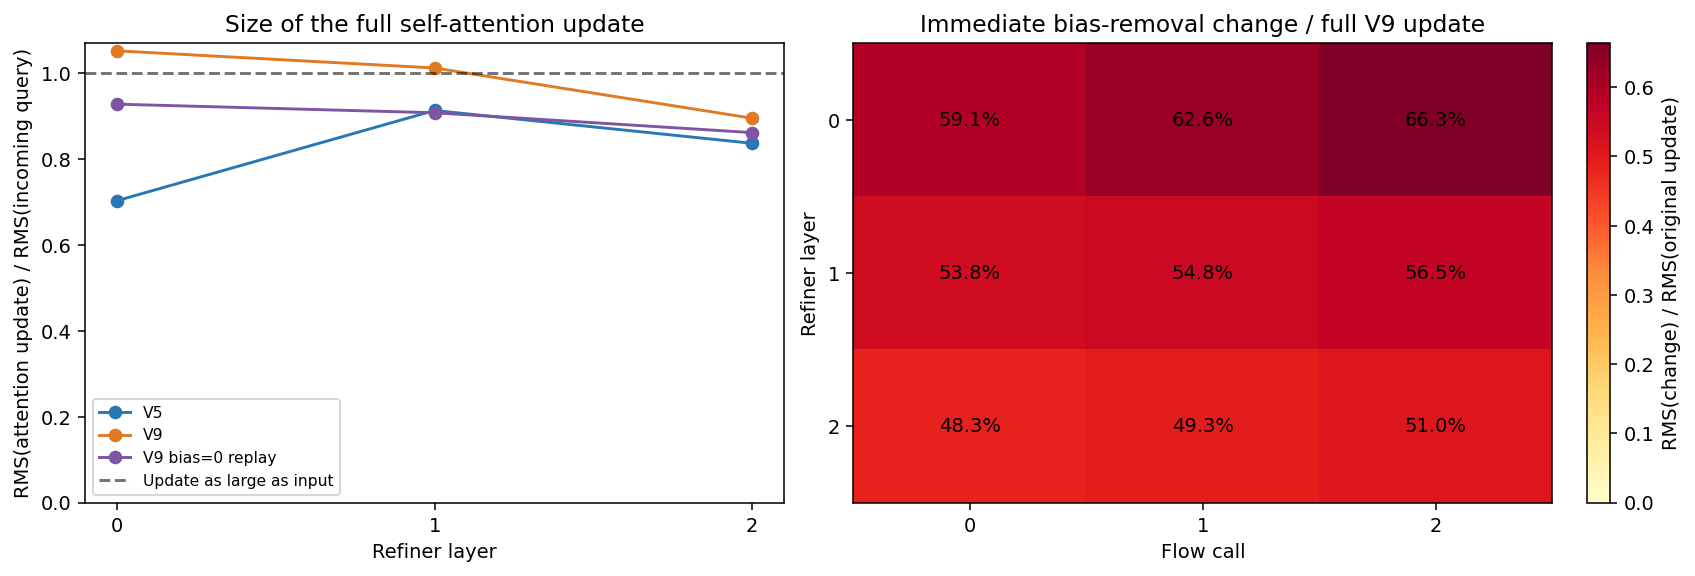

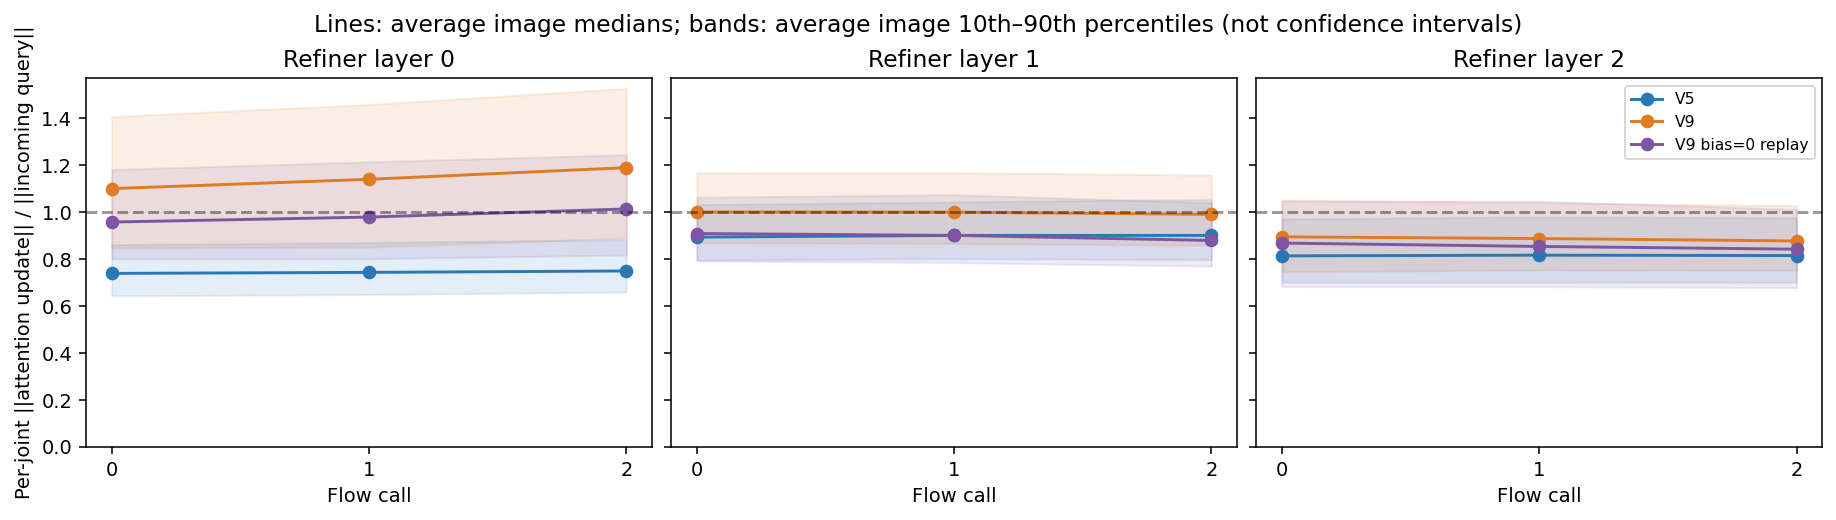

In [4]:
value_columns = ['target_rms', 'value_rms', 'weighted_value_rms', 'attention_output_rms',
                 'output_to_target_rms', 'output_target_cosine', 'bias_change_rms',
                 'bias_change_to_input_rms', 'bias_change_to_update_rms']
assert np.isfinite(attention[value_columns].to_numpy()).all()
display(attention.groupby(['variant', 'layer'])[[
    'target_rms', 'attention_output_rms', 'output_to_target_rms', 'output_target_cosine',
    'bias_change_to_update_rms',
]].mean().round(3))
print('Maximum reconstructed MHA output error:', attention.output_reconstruction_max_abs.max())

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for variant, color in zip(('V5', 'V9', 'V9 bias=0 replay'), ('#2878b5', '#e07a23', '#7e55a3')):
    group = attention[attention.variant == variant].groupby('layer').output_to_target_rms.mean()
    axes[0].plot(group.index, group.values, 'o-', color=color, label=variant)
axes[0].axhline(1, color='black', linestyle='--', alpha=.55, label='Update as large as input')
axes[0].set(xlabel='Refiner layer', ylabel='RMS(attention update) / RMS(incoming query)',
            title='Size of the full self-attention update', xticks=range(3), ylim=(0, None))
axes[0].legend(fontsize=8)
v9_by_call = attention[attention.variant == 'V9'].groupby(['layer', 'step']).mean(numeric_only=True)
change_matrix = v9_by_call.bias_change_to_update_rms.unstack('step').to_numpy()
im = axes[1].imshow(change_matrix, cmap='YlOrRd', vmin=0, aspect='auto')
for layer in range(3):
    for step in range(3):
        axes[1].text(step, layer, f'{100 * change_matrix[layer, step]:.1f}%', ha='center', va='center')
axes[1].set(xlabel='Flow call', ylabel='Refiner layer', xticks=range(3), yticks=range(3),
            title='Immediate bias-removal change / full V9 update')
fig.colorbar(im, ax=axes[1], label='RMS(change) / RMS(original update)')
show_figure(fig, 'attention_update_magnitude.png')

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True, constrained_layout=True)
for layer, axis in enumerate(axes):
    for variant, color in zip(('V5', 'V9', 'V9 bias=0 replay'), ('#2878b5', '#e07a23', '#7e55a3')):
        rows = attention[(attention.variant == variant) & (attention.layer == layer)].groupby('step')
        ratios = rows[['token_ratio_q10', 'token_ratio_median', 'token_ratio_q90']].mean()
        axis.plot(ratios.index, ratios.token_ratio_median, 'o-', color=color, label=variant)
        axis.fill_between(ratios.index, ratios.token_ratio_q10, ratios.token_ratio_q90, color=color, alpha=.12)
    axis.axhline(1, color='black', linestyle='--', alpha=.4)
    axis.set(title=f'Refiner layer {layer}', xlabel='Flow call', xticks=range(3), ylim=(0, None))
axes[0].set_ylabel('Per-joint ||attention update|| / ||incoming query||')
axes[-1].legend(fontsize=8)
fig.suptitle('Lines: average image medians; bands: average image 10th–90th percentiles (not confidence intervals)')
show_figure(fig, 'attention_update_per_joint.png')

## Logit scale and bias

Each row below averages eight images and three flow calls for one decoder layer. The raw quantiles include the softmax-invariant row offset; the centered quantiles and rowwise standard deviation indicate the scale that competes with the V9 bias. `V9 bias=0 replay` reruns the entire sampler and may change later queries. The same-QK zero-bias calculation in the next section holds those queries fixed.

bias  raw_q01  raw_q10  raw_median  raw_q90  raw_q99  \
variant          layer                                                          
V5               0      0.000  -14.697   -4.666       1.394   12.167   23.419   
                 1      0.000   -3.532   -1.067       1.986    7.237   12.019   
                 2      0.000   -4.793   -1.582       2.848   11.853   33.051   
V9               0     -5.297  -16.133   -3.989       3.978   15.707   35.020   
                 1     -5.107   -8.076   -2.760       1.598    9.290   17.316   
                 2     -4.824   -5.564   -2.248       2.908   12.853   32.923   
V9 bias=0 replay 0      0.000  -16.166   -3.991       3.978   15.713   35.013   
                 1      0.000   -6.931   -2.306       1.333    8.112   16.001   
                 2      0.000   -5.459   -2.481       2.511   13.242   32.648   

                        centered_q05  centered_q95  row_logit_std  \
variant          layer                                              
V5               0            -2.394         2.543          1.418   
                 1            -2.377         2.272          1.300   
                 2            -3.472         3.527          1.938   
V9               0            -3.731         3.574          2.033   
                 1            -3.594         3.480          1.913   
                 2            -4.223         4.499          2.393   
V9 bias=0 replay 0            -3.731         3.574          2.034   
                 1            -2.806         2.689          1.468   
                 2            -3.033         3.100          1.635   

                        row_logit_range  neighbor_raw_median  \
variant          layer                                         
V5               0                5.265                1.254   
                 1                4.670                2.607   
                 2                6.856                4.063   
V9               0                7.023                4.223   
                 1                6.776                2.165   
                 2                8.560                3.688   
V9 bias=0 replay 0                7.024                4.223   
                 1                5.164                1.685   
                 2                5.909                2.933   

                        nonneighbor_raw_median  
variant          layer                          
V5               0                       1.508  
                 1                       1.908  
                 2                       2.539  
V9               0                       4.117  
                 1                       1.621  
                 2                       2.806  
V9 bias=0 replay 0                       4.117  
                 1                       1.323  
                 2                       2.478

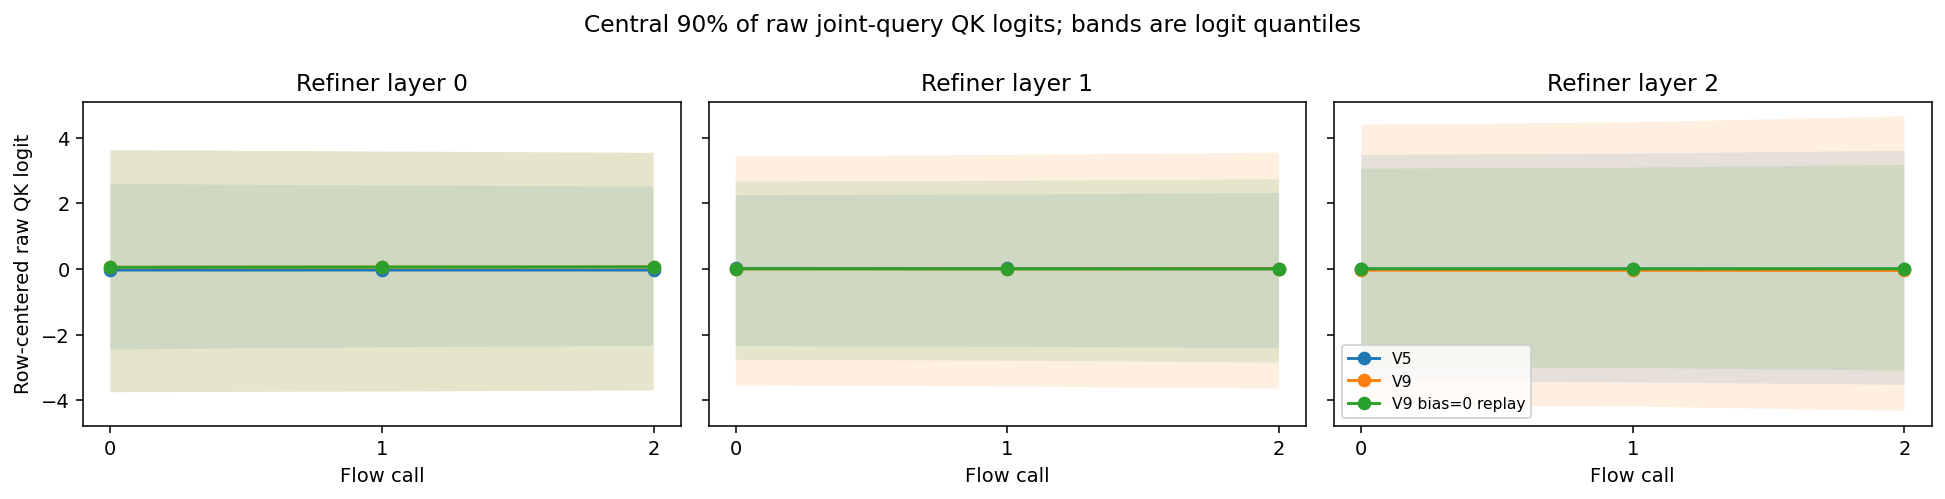

In [5]:
scale_columns = ['bias', 'raw_q01', 'raw_q10', 'raw_median', 'raw_q90', 'raw_q99',
                 'centered_q05', 'centered_q95', 'row_logit_std', 'row_logit_range',
                 'neighbor_raw_median', 'nonneighbor_raw_median']
scale_table = attention.groupby(['variant', 'layer'])[scale_columns].mean().round(3)
display(scale_table)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for layer, axis in enumerate(axes):
    subset = attention[attention.layer == layer]
    for variant, group in subset.groupby('variant'):
        center = group.groupby('step')[['centered_q05', 'centered_median', 'centered_q95']].mean()
        axis.plot(center.index, center.centered_median, marker='o', label=variant)
        axis.fill_between(center.index, center.centered_q05, center.centered_q95, alpha=.12)
    axis.set(title=f'Refiner layer {layer}', xlabel='Flow call', xticks=range(SAMPLING_STEPS))
axes[0].set_ylabel('Row-centered raw QK logit')
axes[-1].legend(loc='best', fontsize=8)
fig.suptitle('Central 90% of raw joint-query QK logits; bands are logit quantiles')
fig.tight_layout()
show_figure(fig)

## Where attention goes

Each mass is summed over all keys of the named relation, then averaged over joint queries, heads, person groups, images, and (in the table) flow calls. Relation sizes differ: every query has one box token, one self joint, a few skeleton neighbors, and many nonneighbors. The same-QK zero-bias column re-softmaxes the **same captured V9 logits** with only its nonneighbor penalty removed; this is the immediate effect of the additive bias at that layer.

box_mass  self_mass  neighbor_mass  nonneighbor_mass
variant          layer                                                      
V5               0        0.0377     0.0655         0.1203            0.7764
                 1        0.0485     0.0898         0.1972            0.6645
                 2        0.0503     0.1712         0.2700            0.5085
V9               0        0.0840     0.3345         0.5218            0.0597
                 1        0.1832     0.1789         0.5339            0.1040
                 2        0.1229     0.2479         0.4889            0.1403
V9 bias=0 replay 0        0.0183     0.0947         0.1562            0.7307
                 1        0.0692     0.0750         0.1635            0.6923
                 2        0.0470     0.1090         0.1716            0.6725

bias  row_logit_std  nonneighbor_mass  \
layer step                                            
0     0    -5.2971         2.0564            0.0610   
      1    -5.2971         2.0344            0.0597   
      2    -5.2971         2.0089            0.0585   
1     0    -5.1071         1.8774            0.1011   
      1    -5.1071         1.9065            0.1035   
      2    -5.1071         1.9546            0.1074   
2     0    -4.8242         2.3272            0.1360   
      1    -4.8242         2.3777            0.1391   
      2    -4.8242         2.4728            0.1459   

            nonneighbor_mass_same_qk_zero_bias  neighbor_mass  \
layer step                                                      
0     0                                 0.7315         0.5207   
      1                                 0.7308         0.5216   
      2                                 0.7297         0.5231   
1     0                                 0.6911         0.5324   
      1                                 0.6901         0.5330   
      2                                 0.6925         0.5362   
2     0                                 0.6494         0.4883   
      1                                 0.6475         0.4890   
      2                                 0.6465         0.4894   

            neighbor_mass_same_qk_zero_bias  
layer step                                   
0     0                              0.1560  
      1                              0.1561  
      2                              0.1567  
1     0                              0.1823  
      1                              0.1839  
      2                              0.1858  
2     0                              0.2011  
      1                              0.2035  
      2                              0.2051

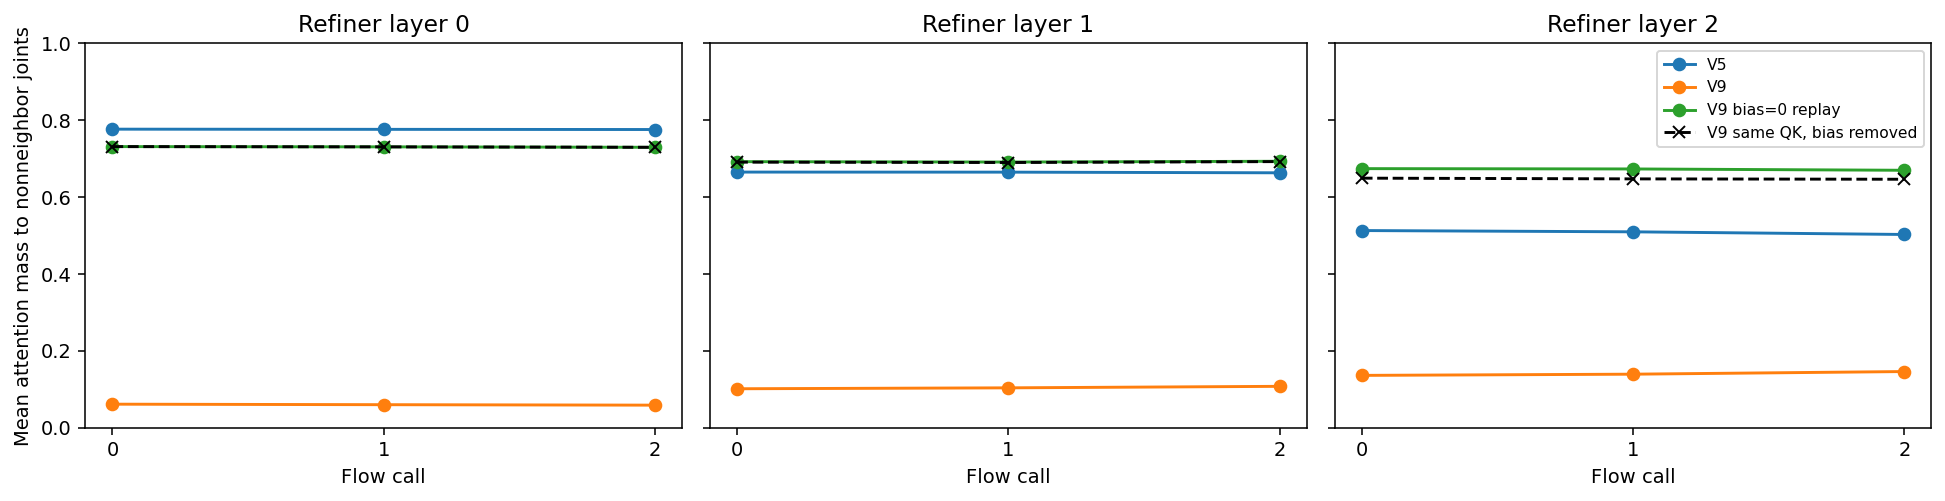

In [6]:
mass_columns = [f'{name}_mass' for name in ('box', 'self', 'neighbor', 'nonneighbor')]
display(attention.groupby(['variant', 'layer'])[mass_columns].mean().round(4))
v9 = attention[attention.variant == 'V9']
display(v9.groupby(['layer', 'step'])[[
    'bias', 'row_logit_std', 'nonneighbor_mass', 'nonneighbor_mass_same_qk_zero_bias',
    'neighbor_mass', 'neighbor_mass_same_qk_zero_bias',
]].mean().round(4))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.7), sharey=True)
for layer, axis in enumerate(axes):
    for variant, group in attention[attention.layer == layer].groupby('variant'):
        per_call = group.groupby('step').nonneighbor_mass.mean()
        axis.plot(per_call.index, per_call.values, marker='o', label=variant)
    immediate = v9[v9.layer == layer].groupby('step').nonneighbor_mass_same_qk_zero_bias.mean()
    axis.plot(immediate.index, immediate.values, 'k--', marker='x', label='V9 same QK, bias removed')
    axis.set(title=f'Refiner layer {layer}', xlabel='Flow call', xticks=range(SAMPLING_STEPS), ylim=(0, 1))
axes[0].set_ylabel('Mean attention mass to nonneighbor joints')
axes[-1].legend(loc='best', fontsize=8)
fig.tight_layout()
show_figure(fig)

## Representative joint-to-key matrices

Rows are the 14 CrowdPose joint queries; columns are the box token and 14 joint keys. Each matrix averages eight images, 50 person groups, and eight heads at the **final flow call** for the indicated layer. Dark/bright patterns show allocation, not pose quality. The skeleton adjacency is encoded only in V9's additive bias.

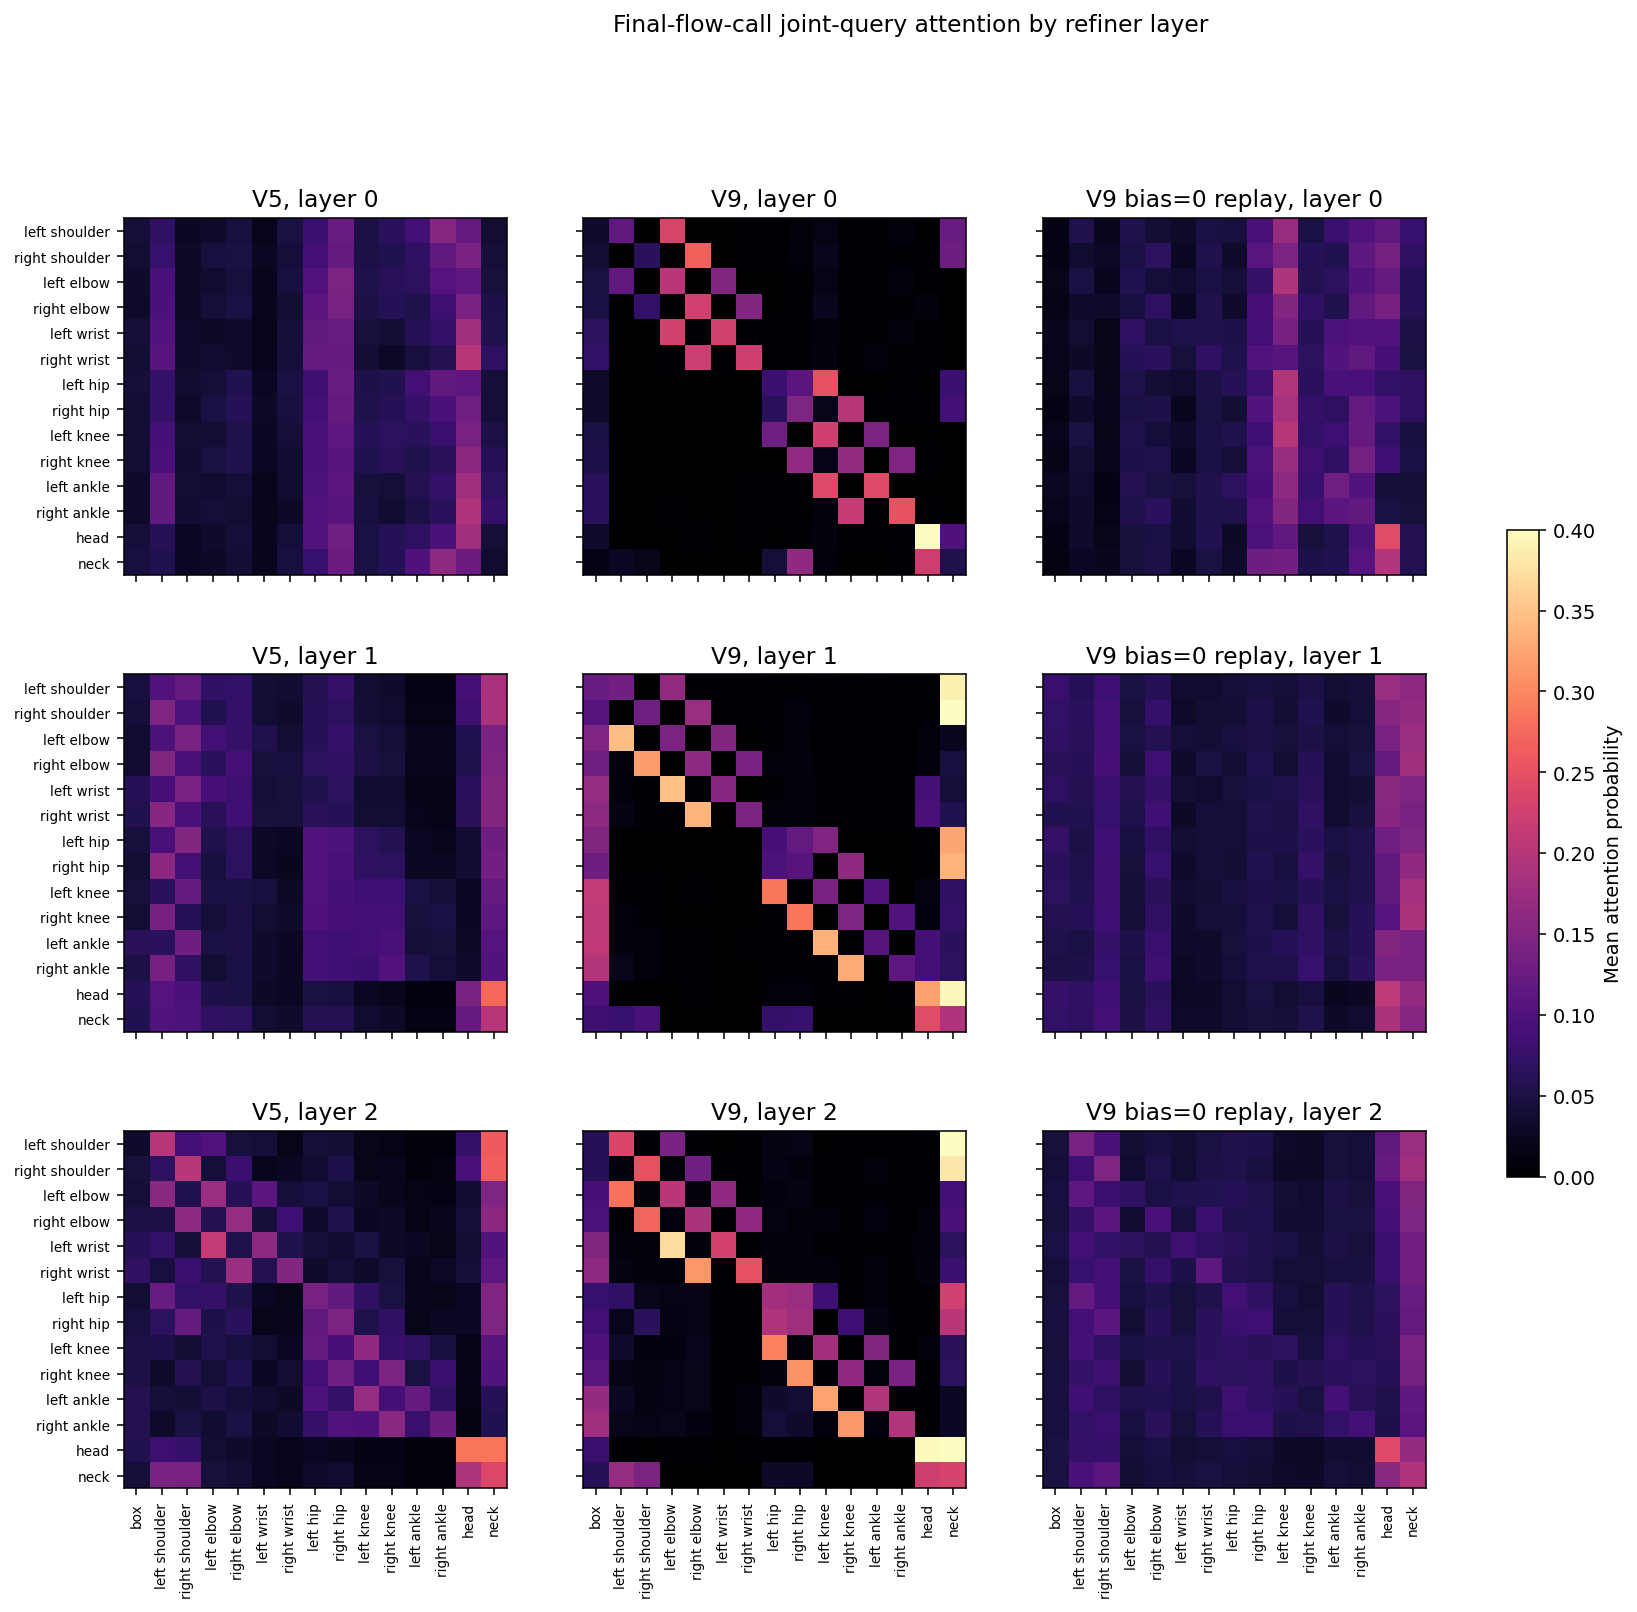

In [7]:
joint_names = ['left shoulder', 'right shoulder', 'left elbow', 'right elbow',
               'left wrist', 'right wrist', 'left hip', 'right hip', 'left knee',
               'right knee', 'left ankle', 'right ankle', 'head', 'neck']
fig, axes = plt.subplots(3, 3, figsize=(15, 12), sharex=True, sharey=True)
for layer in range(3):
    for column, variant in enumerate(('V5', 'V9', 'V9 bias=0 replay')):
        matrices = [row['matrix'] for row in all_rows
                    if row['variant'] == variant and row['layer'] == layer
                    and row['step'] == SAMPLING_STEPS - 1]
        matrix = np.mean(matrices, axis=0)
        im = axes[layer, column].imshow(matrix, vmin=0, vmax=max(.4, float(matrix.max())), cmap='magma')
        axes[layer, column].set_title(f'{variant}, layer {layer}')
        if column == 0:
            axes[layer, column].set_yticks(range(14), joint_names, fontsize=7)
        if layer == 2:
            axes[layer, column].set_xticks(range(15), ['box'] + joint_names,
                                           rotation=90, fontsize=7)
fig.colorbar(im, ax=axes, shrink=.5, label='Mean attention probability')
fig.suptitle('Final-flow-call joint-query attention by refiner layer', y=.995)
show_figure(fig)

## Matched 20-image prediction and performance check

These are **subset AP** numbers, using the repository's CrowdPose postprocessor and evaluator on 20 deterministic validation images. They are useful for the paired intervention, but sampling uncertainty is high. All three variants use epoch-79 checkpoints, aspect-preserving 256/427 resize, S=3, seed `1729 + image_id`, the same annotation subset, pose NMS, and bbox NMS. V9 bias=0 is an inference intervention on the trained V9 checkpoint. We keep every selected image in the GT denominator, including images without detections. Prediction changes below pair surviving final-flow query slots by slot ID before NMS; AP uses the postprocessed detections.

In [8]:
EVAL_COUNT = 20
# An independent deterministic subset; record the exact IDs and GT denominator below.
selection_rng = np.random.default_rng(20261003)
eval_indices = np.sort(selection_rng.choice(len(dataset.samples), size=EVAL_COUNT, replace=False))
eval_samples = [sorted(dataset.samples, key=lambda sample: sample['image_id'])[index]
                for index in eval_indices]
eval_ids = [int(sample['image_id']) for sample in eval_samples]
assert len(eval_ids) == EVAL_COUNT and len(set(eval_ids)) == EVAL_COUNT
annotation_data = json.loads(ANNOTATIONS.read_text())
annotation_count = sum(int(row['image_id'] in set(eval_ids)) for row in annotation_data['annotations'])
print({'selection_seed': 20261003, 'image_count': EVAL_COUNT, 'annotation_count': annotation_count,
       'image_ids': eval_ids})


def final_slot_differences(baseline, changed, sample):
    before = baseline['flow_step_diagnostics'][-1]
    after = changed['flow_step_diagnostics'][-1]
    first_ids = before['selected_slot_ids'][0].tolist()
    lookup = {int(slot): index for index, slot in enumerate(after['selected_slot_ids'][0].tolist())}
    pairs = [(index, lookup[int(slot)]) for index, slot in enumerate(first_ids) if int(slot) in lookup]
    if not pairs:
        return {'shared_slots': 0, 'pose_xy_l1': np.nan, 'box_cxcywh_l1': np.nan, 'score_l1': np.nan}
    first_index, second_index = map(list, zip(*pairs))
    scale = before['pred_keypoints'].new_tensor([sample['img_hw'][1], sample['img_hw'][0]])
    pixel_change = ((before['pred_keypoints'][0, first_index, :28] -
                     after['pred_keypoints'][0, second_index, :28]).reshape(-1, 14, 2) * scale).norm(dim=-1)
    return {
        'joint_displacement_px_mean': float(pixel_change.mean()),
        'joint_displacement_px_median': float(pixel_change.median()),
        'shared_slots': len(pairs),
        'pose_xy_l1': float((before['pred_keypoints'][0, first_index, :28] -
                              after['pred_keypoints'][0, second_index, :28]).abs().mean()),
        'box_cxcywh_l1': float((before['pred_boxes'][0, first_index] -
                                 after['pred_boxes'][0, second_index]).abs().mean()),
        'score_l1': float((before['pred_logits'][0, first_index].sigmoid() -
                            after['pred_logits'][0, second_index].sigmoid()).abs().mean()),
    }


def infer_one(model, sample):
    image = resize_crowdpose_eval_image(
        read_image(sample['img_path']).float().div(255), shortest_side=256, max_size=427,
    ).to(DEVICE)
    seed_flow_sampling(flow_seed=FLOW_SEED, image_id=sample['image_id'])
    with torch.no_grad():
        output = model.sample_keypoints(image[None], collect_step_diagnostics=True)
        original_size = torch.tensor([sample['img_hw']], dtype=torch.float32, device=DEVICE)
        nms_size = torch.tensor([image.shape[-2:]], dtype=torch.float32, device=DEVICE)
        result = postprocess_crowdpose(output, original_size, nms_target_sizes=nms_size)
        records = crowdpose_result_records(sample['image_id'], result)
    return output, records

all_predictions = {}
paired_changes = []
prediction_examples = []
for family in ('V5', 'V9'):
    model, config = load_poseflow_model(
        RUNS[family] / 'checkpoints/epoch079.ckpt', RUNS[family] / '.hydra/config.yaml',
    )
    model.to(DEVICE).eval()
    assert config.flow_sampling_steps == SAMPLING_STEPS and not model.flow_ensemble
    predictions = {family: []}
    if family == 'V9':
        predictions['V9 bias=0'] = []
        learned_bias = model.off_edge_attention_bias.detach().clone()
    for sample in eval_samples:
        baseline, records = infer_one(model, sample)
        predictions[family].extend(records)
        if family == 'V9':
            try:
                with torch.no_grad():
                    model.off_edge_attention_bias.zero_()
                changed, changed_records = infer_one(model, sample)
            finally:
                with torch.no_grad():
                    model.off_edge_attention_bias.copy_(learned_bias)
            predictions['V9 bias=0'].extend(changed_records)
            paired_changes.append({'image_id': sample['image_id'],
                                   **final_slot_differences(baseline, changed, sample)})
            if len(prediction_examples) < 3:
                before = baseline['flow_step_diagnostics'][-1]
                after = changed['flow_step_diagnostics'][-1]
                ids = before['selected_slot_ids'][0].tolist()
                lookup = {int(slot): index for index, slot in enumerate(after['selected_slot_ids'][0].tolist())}
                shared = [index for index, slot in enumerate(ids) if int(slot) in lookup]
                if shared:
                    scores = before['pred_logits'][0].sigmoid().amax(-1)
                    selected = max(shared, key=lambda index: float(scores[index]))
                    changed_index = lookup[int(ids[selected])]
                    prediction_examples.append({
                        'sample': sample, 'slot_id': int(ids[selected]),
                        'before_pose': before['pred_keypoints'][0, selected, :28].detach().cpu().reshape(14, 2),
                        'after_pose': after['pred_keypoints'][0, changed_index, :28].detach().cpu().reshape(14, 2),
                        'before_box': before['pred_boxes'][0, selected].detach().cpu(),
                        'after_box': after['pred_boxes'][0, changed_index].detach().cpu(),
                        'before_score': float(scores[selected]),
                        'after_score': float(after['pred_logits'][0, changed_index].sigmoid().max()),
                    })
    if family == 'V9':
        torch.testing.assert_close(model.off_edge_attention_bias, learned_bias)
        replay, replay_records = infer_one(model, eval_samples[0])
        assert replay_records == [r for r in predictions['V9']
                                  if r['image_id'] == eval_samples[0]['image_id']]
    all_predictions.update(predictions)
    del model
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
print({name: len(records) for name, records in all_predictions.items()})
change_table = pd.DataFrame(paired_changes)
display(change_table.round(4))
display(change_table[['shared_slots', 'pose_xy_l1', 'box_cxcywh_l1', 'score_l1', 'joint_displacement_px_mean']].mean().to_frame('V9 bias=0 vs V9'))

{'selection_seed': 20261003, 'image_count': 20, 'annotation_count': 72, 'image_ids': [100836, 101191, 102862, 105616, 106211, 106540, 106601, 107055, 108106, 109418, 110862, 112533, 112973, 113072, 114636, 115994, 117135, 118047, 119186, 119570]}


{'V5': 159, 'V9': 168, 'V9 bias=0': 220}


,image_id,joint_displacement_px_mean,joint_displacement_px_median,shared_slots,pose_xy_l1,box_cxcywh_l1,score_l1
0,100836,13.4934,9.4781,50,0.0162,0.0041,0.0195
1,101191,11.7263,8.7766,50,0.0149,0.0055,0.0755
2,102862,19.3706,14.1810,48,0.0236,0.0035,0.0484
3,105616,11.5237,8.0671,49,0.0147,0.0070,0.0717
4,106211,25.3031,17.5193,49,0.0254,0.0170,0.0397
5,106540,32.4406,10.2239,47,0.0360,0.0291,0.0678
6,106601,25.3961,19.0369,50,0.0233,0.0108,0.0157
7,107055,32.0764,17.9961,47,0.0384,0.0218,0.0138
8,108106,14.1464,10.2357,50,0.0162,0.0057,0.0461
9,109418,38.1049,31.6227,49,0.0262,0.0082,0.0239


,V9 bias=0 vs V9
shared_slots,48.350000
pose_xy_l1,0.027008
box_cxcywh_l1,0.010887
score_l1,0.041228
joint_displacement_px_mean,32.216881


In [9]:
metric_rows = []
artifact_dir = ROOT / 'tmp/poseflow_v5_v9_joint_attention'
artifact_dir.mkdir(parents=True, exist_ok=True)
for variant, records in all_predictions.items():
    path = artifact_dir / (variant.lower().replace(' ', '_').replace('=', '') + '_20_images.json')
    write_crowdpose_results(records, path)
    with contextlib.redirect_stdout(io.StringIO()):
        metrics = evaluate_crowdpose_results(path, ANNOTATIONS, image_ids=eval_ids)
    assert np.isfinite(list(metrics.values())).all()
    metric_rows.append({'variant': variant, 'images': len(eval_ids), 'GT annotations': annotation_count,
                        'detections': len(records), 'keypoint AP': metrics['AP'],
                        'bbox AP': metrics['bbox/AP'],
                        'bbox AP50': metrics['bbox/AP50'], 'bbox AP75': metrics['bbox/AP75']})
metric_table = pd.DataFrame(metric_rows).set_index('variant')
display(metric_table.round(4))
display((metric_table.loc['V9 bias=0', ['keypoint AP', 'bbox AP']] -
         metric_table.loc['V9', ['keypoint AP', 'bbox AP']]).to_frame('bias=0 minus V9').round(4))
print('Evaluator: crowdposetools COCOeval, exact selected image IDs; score/NMS: repository defaults')

,images,GT annotations,detections,keypoint AP,bbox AP,bbox AP50,bbox AP75
variant,,,,,,,
V5,20,72,159,0.7986,0.7116,0.8183,0.7920
V9,20,72,168,0.8098,0.7298,0.8353,0.7994
V9 bias=0,20,72,220,0.5495,0.6806,0.7994,0.7628


,bias=0 minus V9
keypoint AP,-0.2603
bbox AP,-0.0492


Evaluator: crowdposetools COCOeval, exact selected image IDs; score/NMS: repository defaults


## What changes in the final pose and box?

These arrows show the **complete V9 bias-zero replay's final prediction changes**, including later blocks, flow calls, and candidate selection. They are not a conversion of the internal attention vector to pixels. For each of the first three evaluation images, select the highest-scoring baseline query slot that survives in both predictions. Green is trained V9; magenta is V9 with its bias zeroed; arrows connect the same joints. Dashed rectangles show predicted boxes. Titles report that person's mean joint displacement in original-image pixels and both scores. These are pre-NMS paired slots; the AP table uses post-NMS detections.

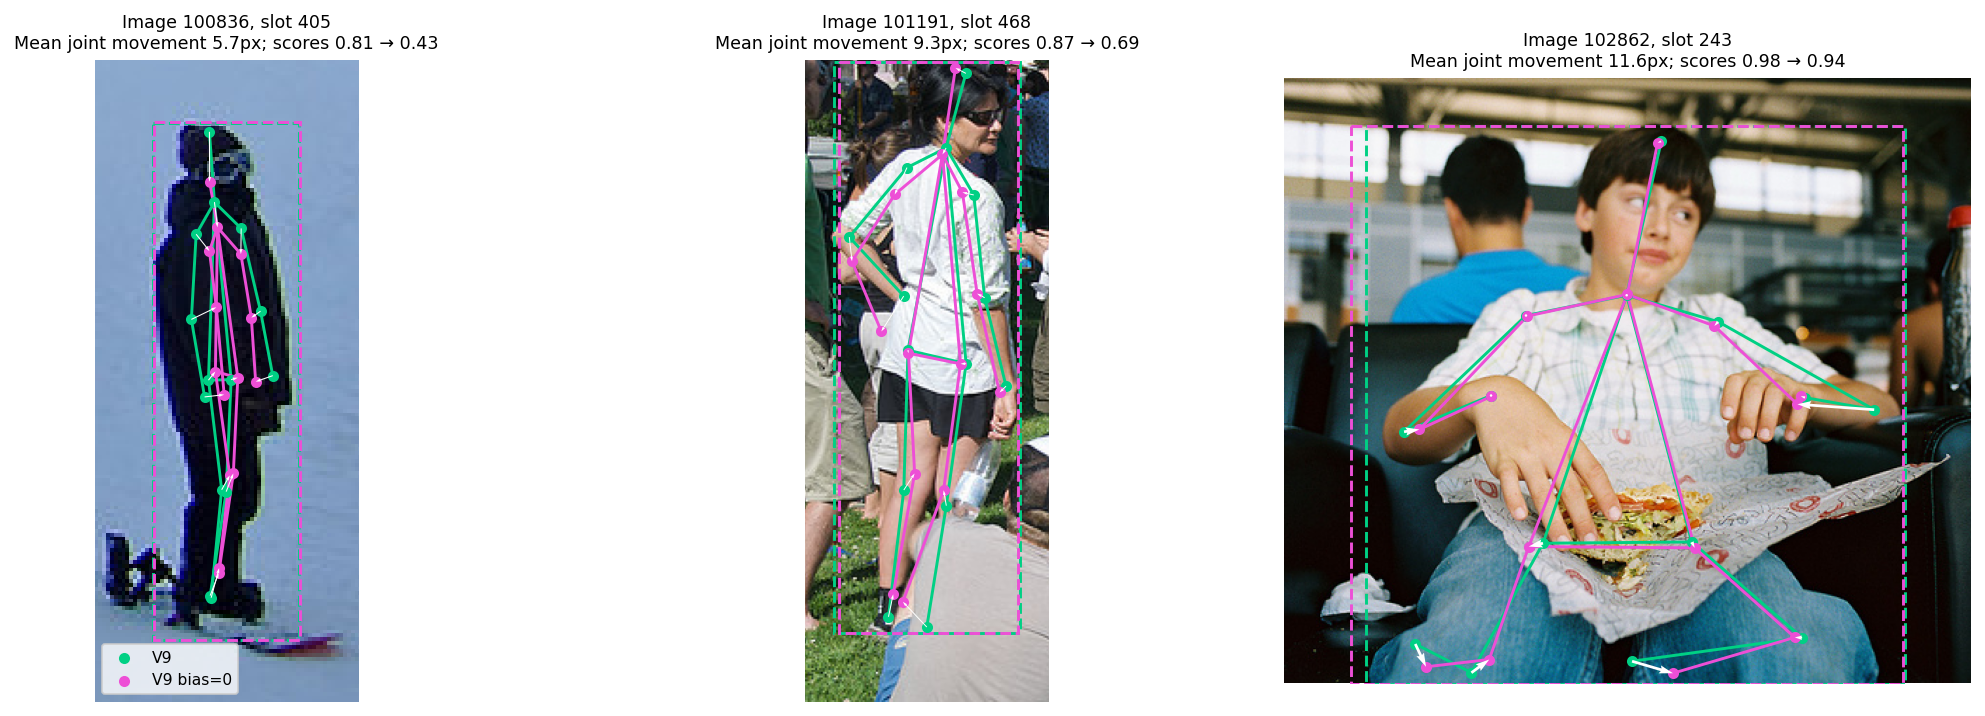

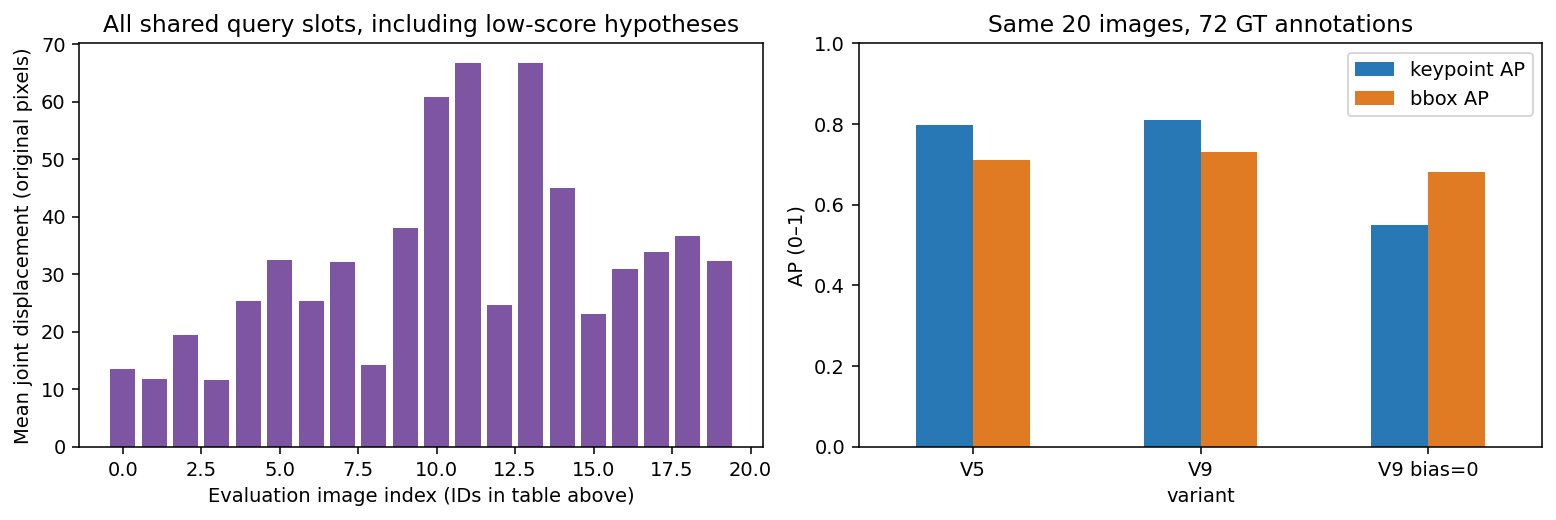

In [10]:
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(1, len(prediction_examples), figsize=(15, 5), constrained_layout=True)
for axis, example in zip(np.atleast_1d(axes), prediction_examples):
    sample = example['sample']
    height, width = sample['img_hw']
    scale = np.array([width, height])
    before = example['before_pose'].numpy() * scale
    after = example['after_pose'].numpy() * scale
    axis.imshow(read_image(sample['img_path']).permute(1, 2, 0).numpy())
    for pose, color, label in ((before, '#00d084', 'V9'), (after, '#ed4fd6', 'V9 bias=0')):
        axis.scatter(pose[:, 0], pose[:, 1], s=22, c=color, label=label, zorder=3)
        for source, destination in CROWDPOSE_EDGE_LIST:
            axis.plot(pose[[source, destination], 0], pose[[source, destination], 1], color=color, linewidth=1.5)
    axis.quiver(before[:, 0], before[:, 1], after[:, 0] - before[:, 0], after[:, 1] - before[:, 1],
                angles='xy', scale_units='xy', scale=1, color='white', width=.004, zorder=4)
    box_corners = []
    for name, color in (('before_box', '#00d084'), ('after_box', '#ed4fd6')):
        cx, cy, box_width, box_height = example[name].numpy() * np.array([width, height, width, height])
        lower = np.array([cx - box_width / 2, cy - box_height / 2])
        upper = lower + np.array([box_width, box_height])
        box_corners.extend([lower, upper])
        axis.add_patch(Rectangle(lower, box_width, box_height, fill=False, edgecolor=color, linestyle='--', linewidth=1.5))
    points = np.vstack([before, after, box_corners])
    lower, upper = points.min(0), points.max(0)
    padding = np.maximum((upper - lower) * .12, 15)
    axis.set_xlim(max(0, lower[0] - padding[0]), min(width, upper[0] + padding[0]))
    axis.set_ylim(min(height, upper[1] + padding[1]), max(0, lower[1] - padding[1]))
    displacement = np.linalg.norm(after - before, axis=-1).mean()
    axis.set_title(f"Image {sample['image_id']}, slot {example['slot_id']}\nMean joint movement {displacement:.1f}px; scores {example['before_score']:.2f} → {example['after_score']:.2f}", fontsize=9)
    axis.axis('off')
axes[0].legend(loc='lower left', fontsize=8)
show_figure(fig, 'paired_pose_and_box_changes.png')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
axes[0].bar(range(len(change_table)), change_table.joint_displacement_px_mean, color='#7e55a3')
axes[0].set(xlabel='Evaluation image index (IDs in table above)', ylabel='Mean joint displacement (original pixels)',
            title='All shared query slots, including low-score hypotheses')
metric_table[['keypoint AP', 'bbox AP']].plot.bar(ax=axes[1], color=['#2878b5', '#e07a23'], rot=0)
axes[1].set(ylabel='AP (0–1)', ylim=(0, 1), title='Same 20 images, 72 GT annotations')
show_figure(fig, 'prediction_movement_and_ap.png')

## Interpretation boundaries

- The reconstruction check establishes that the measured probabilities match the model's actual self-attention weights for the selected clean rows. The V9 learned parameter is an **additive logit penalty**, not a probability multiplier.
- V5 and V9 differ in all learned attention projections after separate training. Their direct logit/mass differences therefore describe the checkpoints but do not isolate the bias. The same-QK zero-bias calculation isolates the immediate softmax effect; the bias-zero replay also changes subsequent layer and flow inputs.
- Attention mass alone does not show whether the attended information improves keypoint AP. The 20-image subset AP and paired prediction changes above test whether this intervention reaches final outputs; they do not estimate full-validation AP.

## Measured answer

On these eight images, V5 allocates **77.6%, 66.5%, and 50.9%** of clean joint-query attention to nonneighbor joints in refiner layers 0, 1, and 2. V9 allocates **6.0%, 10.4%, and 14.0%**. Its learned additive penalties at epoch 79 are **−5.297, −5.107, and −4.824**. The unbiased within-row QK logit standard deviations average **2.03, 1.91, and 2.39** for V9, compared with **1.42, 1.30, and 1.94** for V5. Raw logits have much wider global quantiles because row offsets do not affect softmax.

Removing the V9 penalty while holding each measured QK matrix fixed gives nonneighbor masses of roughly **73.1%, 69.1%, and 64.8%**. The separately rerun bias-zero V9 sampler yields **73.1%, 69.2%, and 67.3%**. The first measure isolates the immediate mask effect; the replay also changes later activations. The attention-weight reconstruction error is below **1×10⁻⁶**, and the restored V9 model reproduces its original predictions.

Thus the similar V5/V9 loss curves do **not** mean their joint attention is the same. The small-sample evaluation below does not establish why full-validation AP is similar: the decoder may compensate elsewhere, the removed long-range reads may be redundant, or the changed attention could affect cases outside this small sample. Those are hypotheses for separate quality-linked tests.

The added 20-image diagnostic gives V5 **0.7986 keypoint AP / 0.7116 bbox AP**, V9 **0.8098 / 0.7298**, and V9 with its bias zeroed **0.5495 / 0.6806** (72 GT annotations; 159, 168, and 220 detections respectively). Thus removing the learned bias in the trained V9 model changes predictions and sharply lowers keypoint AP on this subset. It does not show the AP of a V9 model trained without the bias. Across the 20 images, 48.35 of 50 final query slots on average retain the same ID, yet their normalized keypoint coordinates change by 0.0270 absolute on average; normalized box coordinates change by 0.0109. The reconstructed attention output is within 7.63×10⁻⁶ of PyTorch's output and has RMS comparable to the incoming query in V9. These observations rule out the attention output being numerically absent on this sample; they do not isolate its contribution after cross-attention and later decoding.
